In [2]:
# 1. Import library dan pengaturan seed

import os
import re
import random
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.22.0-rc1
GPU tersedia: []


In [3]:
# 2. Membaca dataset (11 kelas) dan membentuk grup rekaman sumber

DATASET_DIR = Path("IRMAS-TrainingData")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        "Folder IRMAS-TrainingData tidak ditemukan. "
        "Periksa lokasi notebook dan dataset."
    )

audio_paths = []
labels = []
groups = []

for folder in sorted(DATASET_DIR.iterdir()):
    if not folder.is_dir():
        continue

    for file in folder.glob("*.wav"):
        audio_paths.append(str(file))
        labels.append(folder.name)

        # Mengelompokkan segmen dari rekaman sumber yang sama
        nama_sumber = re.sub(r"__\d+$", "", file.stem)
        groups.append(nama_sumber)

class_names = sorted(set(labels))
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

y = np.array([class_to_idx[label] for label in labels])
groups = np.array(groups)

print("Jumlah audio:", len(audio_paths))
print("Jumlah kelas:", len(class_names))
print("Kelas:", class_names)
print("Jumlah grup sumber:", len(np.unique(groups)))

assert len(class_names) == 11
assert len(audio_paths) == len(y) == len(groups)


Jumlah audio: 6705
Jumlah kelas: 11
Kelas: ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']
Jumlah grup sumber: 2273


In [ ]:
# 3. Pembagian data berbasis grup

skf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

dummy_X = np.zeros(len(y))

folds = list(
    skf.split(dummy_X, y, groups)
)

test_idx = folds[0][1]
val_idx = folds[1][1]

train_idx = np.concatenate([
    folds[2][1],
    folds[3][1],
    folds[4][1]
])

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# Memastikan tidak ada grup yang bocor
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Pengecekan group leakage: AMAN")


Train: 4022
Validation: 1342
Test: 1341
Pengecekan group leakage: AMAN


In [ ]:
# 4. Ekstraksi mel-spectrogram

SR = 22050
DURATION = 3
N_MELS = 96
N_FFT = 2048
HOP_LENGTH = 512
TIME_STEPS = 128

def extract_mel(path):
    audio, _ = librosa.load(
        path,
        sr=SR,
        mono=True,
        duration=DURATION
    )

    target_length = SR * DURATION

    if len(audio) < target_length:
        audio = np.pad(
            audio,
            (0, target_length - len(audio))
        )
    else:
        audio = audio[:target_length]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=20,
        fmax=SR // 2
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    # Normalisasi ke rentang 0 sampai 1
    mel_db = (mel_db + 80) / 80

    # Menyamakan jumlah time steps
    mel_db = mel_db[:, :TIME_STEPS]

    if mel_db.shape[1] < TIME_STEPS:
        mel_db = np.pad(
            mel_db,
            ((0, 0), (0, TIME_STEPS - mel_db.shape[1]))
        )

    return mel_db.astype(np.float32)


X_mel = np.array([
    extract_mel(path)
    for path in audio_paths
])

X_mel = X_mel[..., np.newaxis]

print("Shape Mel-Spectrogram:", X_mel.shape)


Shape Mel-Spectrogram: (6705, 96, 128, 1)


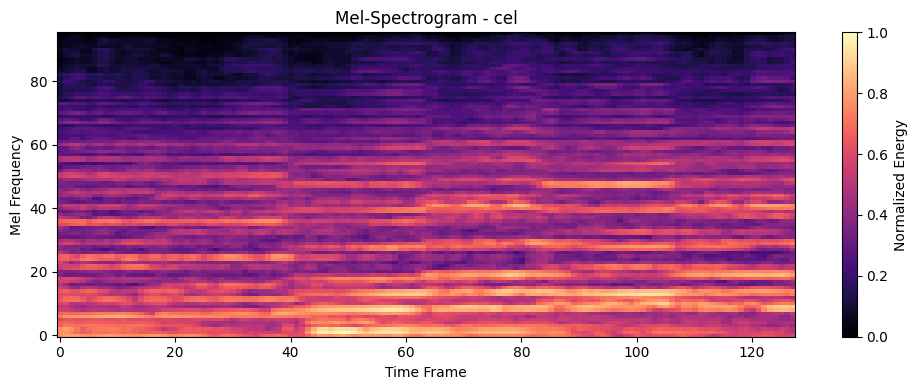

In [6]:
# 5. Contoh mel-spectrogram

plt.figure(figsize=(10, 4))

plt.imshow(
    X_mel[0, :, :, 0],
    aspect="auto",
    origin="lower",
    cmap="magma"
)

plt.colorbar(label="Normalized Energy")
plt.xlabel("Time Frame")
plt.ylabel("Mel Frequency")
plt.title(
    f"Mel-Spectrogram - {class_names[y[0]]}"
)

plt.tight_layout()
plt.show()


In [7]:
# 6. Normalisasi (z-score)

X_train = X_mel[train_idx]
X_val = X_mel[val_idx]
X_test = X_mel[test_idx]

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

mean = X_train.mean()
std = X_train.std() + 1e-7

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (4022, 96, 128, 1)
Validation: (1342, 96, 128, 1)
Test: (1341, 96, 128, 1)


In [17]:
# 6.1 simpan mean dan std cnn

import joblib

cnn_preprocessing = {
    "mean": float(mean),
    "std": float(std),
    "sr": SR,
    "duration": DURATION,
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "time_steps": TIME_STEPS
}

joblib.dump(
    cnn_preprocessing,
    "cnn_preprocessing.joblib"
)

print("Preprocessing CNN berhasil disimpan!")


Preprocessing CNN berhasil disimpan!


In [15]:
# 7. Arsitektur CNN

from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(N_MELS, TIME_STEPS, 1)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 96, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 48, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,499 (435.54 KB)

 Trainable params: 111,051 (433.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [9]:
# 8. Pelatihan

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights)
}

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001
    )
]

history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 28s 209ms/step - accuracy: 0.2636 - loss: 2.1440 - val_accuracy: 0.1632 - val_loss: 2.7280 - learning_rate: 0.0010
Epoch 2/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 25s 200ms/step - accuracy: 0.3655 - loss: 1.9069 - val_accuracy: 0.1222 - val_loss: 3.8232 - learning_rate: 0.0010
Epoch 3/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 27s 213ms/step - accuracy: 0.4301 - loss: 1.7414 - val_accuracy: 0.2288 - val_loss: 2.9186 - learning_rate: 0.0010
Epoch 4/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 26s 210ms/step - accuracy: 0.4684 - loss: 1.6058 - val_accuracy: 0.1773 - val_loss: 2.6557 - learning_rate: 0.0010
Epoch 5/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 25s 195ms/step - accuracy: 0.5149 - loss: 1.4777 - val_accuracy: 0.3174 - val_loss: 2.0087 - learning_rate: 0.0010
Epoch 6/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 25s 199ms/step - accuracy: 0.5460 - loss: 1.3791 - val_accuracy: 0.3994 - val_loss: 1.7768 - learning_rate: 0.0010
Epoch 7/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 25s 197ms/step - accuracy: 0.5

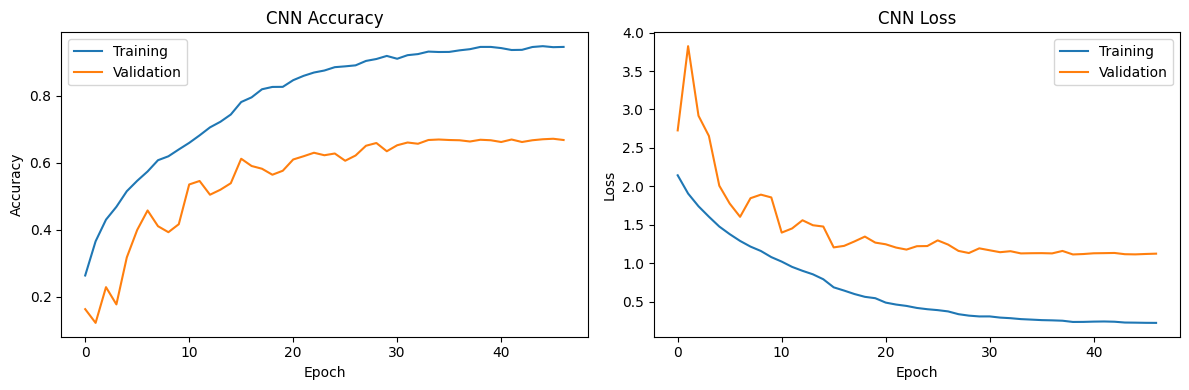

In [10]:
# 8. Kurva akurasi dan loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [11]:
# 9. Evaluasi pada data test

y_prob = cnn_model.predict(X_test)

y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("CNN TEST RESULTS")
print("================")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Macro :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))


42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
CNN TEST RESULTS
Accuracy : 0.7136
Precision: 0.6963
Recall   : 0.6977
F1 Macro : 0.6962

Classification Report:
              precision    recall  f1-score   support

         cel       0.58      0.57      0.58        77
         cla       0.53      0.58      0.55       101
         flu       0.60      0.62      0.61        90
         gac       0.73      0.80      0.77       128
         gel       0.71      0.64      0.67       152
         org       0.83      0.88      0.85       136
         pia       0.78      0.81      0.79       144
         sax       0.59      0.54      0.57       125
         tru       0.81      0.75      0.78       116
         vio       0.60      0.57      0.58       116
         voi       0.89      0.91      0.90       156

    accuracy                           0.71      1341
   macro avg       0.70      0.70      0.70      1341
weighted avg       0.71      0.71      0.71      1341



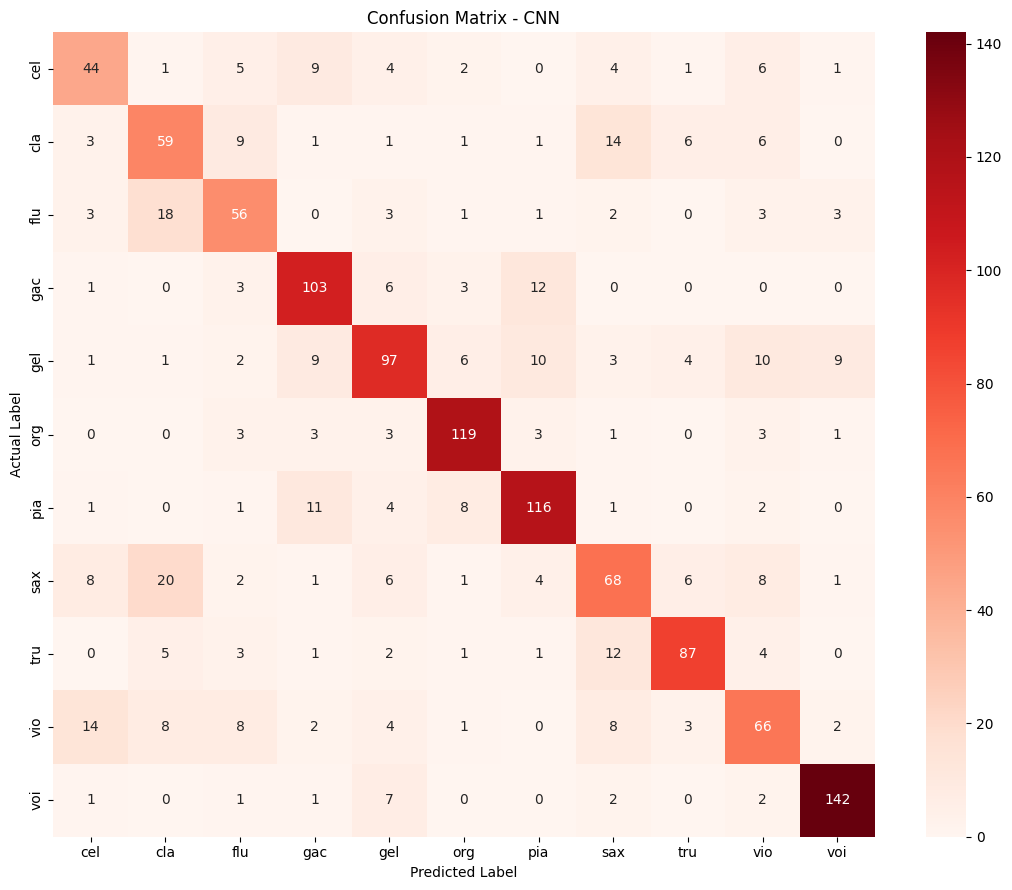

In [22]:
# 10. Confusion matrix CNN

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - CNN")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
cnn_model.save("musictype_cnn.keras")